# Normalizace průběhů a porovnání tvaru přechodové charakteristiky

Cíl: odstranit rozdíly v absolutní velikosti amplitudy i výchozí hladině $y_0$ a porovnat čistě **tvar přechodové charakteristiky** napříč všemi teplotami (`data_correctedTimeStamp/`, 15 Hz).

### Obsah analýzy
1. **Načtení dat a výpočet normalizací** – klidová hladina $y_0$, detekce začátku děje $t_0$, normalizace signálu $\tilde{y}(t) \in [-1, 1]$ a normalizace obálky rychlosti změny $v_{\text{norm}}(t) \in [0, 1]$.
2. **Normalizované průběhy signálu $\tilde{y}(t)$** – porovnání tvaru všech souborů v jednom grafu.
3. **Normalizovaný tvar obálky přechodové charakteristiky $v_{\text{norm}}(\tau)$** – zarovnáno na začátek děje $\tau = t - t_0$, odděleně pro $T < 24\,^\circ\text{C}$ a $T > 24\,^\circ\text{C}$ včetně mediánového tvaru.
4. **Heatmapa tvaru přechodové charakteristiky** (čas $\tau$ vs. teplota $T$).
5. **Kvantitativní metriky tvaru** (doba náběhu, doba poklesu na 50 % a 10 %, doba trvání 90 % energie) v závislosti na teplotě + přímé překrytí vybraných teplot.

In [1]:
import re
from pathlib import Path

import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter1d

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DATA_DIR = Path("..") / "data_correctedTimeStamp"
if not DATA_DIR.is_dir():
    DATA_DIR = Path("data_correctedTimeStamp")
assert DATA_DIR.is_dir(), f"Adresář nenalezen: {DATA_DIR.resolve()}"

FS = 15.0
DT = 1.0 / FS
SMOOTH_WIN_S = 3.0  # šířka vyhlazovacího okna [s] pro obálku |Δy|
SMOOTH_N = max(3, int(round(SMOOTH_WIN_S * FS)))


def extract_temp(path: Path) -> int:
    m = re.search(r"(-?\d+)", path.stem)
    return int(m.group(1)) if m else 9999


def load_starlab_file(path: Path) -> tuple[np.ndarray, np.ndarray]:
    t_vals, y_vals = [], []
    in_data = False
    with path.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            if not in_data:
                if "Timestamp" in line and "Channel A" in line:
                    in_data = True
                continue
            parts = line.strip().split()
            if len(parts) >= 2:
                t_vals.append(float(parts[0]))
                y_vals.append(float(parts[1]))
    return np.asarray(t_vals, dtype=np.float64), np.asarray(y_vals, dtype=np.float64)


files = sorted(DATA_DIR.glob("*.txt"), key=extract_temp)
datasets = {}

for p in files:
    temp = extract_temp(p)
    t, y = load_starlab_file(p)

    # Klidová fáze před dějem (20–120 s)
    base_mask = (t >= 20.0) & (t <= 120.0)
    y0 = float(np.mean(y[base_mask]))
    sd0 = float(np.std(y[base_mask]))

    # 1) Normalizace samotného signálu y(t) podle vlastní amplitudy od klidové hladiny y0
    y_centered = y - y0
    amp_y = float(np.max(np.abs(y_centered)))
    y_norm_centered = y_centered / amp_y if amp_y > 0 else np.zeros_like(y)

    # Min-Max normalizace do [0, 1]
    y_span = float(np.max(y) - np.min(y))
    y_norm_01 = (y - np.min(y)) / y_span if y_span > 0 else np.zeros_like(y)

    # 2) Absolutní změna |Δy| a její vyhlazená obálka normalizovaná na vlastní maximum [0, 1]
    t_diff = t[1:]
    dy_abs = np.abs(np.diff(y))
    env = uniform_filter1d(dy_abs, size=SMOOTH_N)
    # Hledáme maximum obálky až v aktivní části (t >= 120 s)
    active_mask = t_diff >= 120.0
    env_max = float(np.max(env[active_mask]))
    env_norm = env / env_max if env_max > 0 else np.zeros_like(env)

    # 3) Detekce začátku děje t0 (první překročení 10 % maxima obálky po t = 120 s)
    idx_peak = int(np.where(active_mask)[0][np.argmax(env[active_mask])])
    t_peak = float(t_diff[idx_peak])

    # Hledání t0 zpětně od maxima k 10 % obálky (v rámci t >= 120 s)
    onset_candidates = np.where((t_diff >= 120.0) & (t_diff <= t_peak) & (env_norm >= 0.10))[0]
    t0 = float(t_diff[onset_candidates[0]]) if len(onset_candidates) > 0 else 140.0

    # 4) Metriky tvaru přechodové charakteristiky (v relativním čase τ = t - t0)
    tau_diff = t_diff - t0
    post_peak = np.where(t_diff >= t_peak)[0]
    below_50 = post_peak[env_norm[post_peak] <= 0.50]
    below_10 = post_peak[env_norm[post_peak] <= 0.10]
    tau_peak = t_peak - t0
    tau_50 = float(t_diff[below_50[0]] - t0) if len(below_50) > 0 else np.nan
    tau_10 = float(t_diff[below_10[0]] - t0) if len(below_10) > 0 else np.nan

    # Doba, za kterou proběhne 90 % celkové změny po t0
    post_t0 = t_diff >= t0
    cum_dy = np.cumsum(dy_abs[post_t0])
    if len(cum_dy) > 0 and cum_dy[-1] > 0:
        cum_norm = cum_dy / cum_dy[-1]
        tau_90_energy = float(tau_diff[post_t0][np.searchsorted(cum_norm, 0.90)])
    else:
        cum_norm = np.array([])
        tau_90_energy = np.nan

    datasets[temp] = {
        "name": p.name,
        "t": t,
        "y": y,
        "y0": y0,
        "amp_y": amp_y,
        "y_norm_centered": y_norm_centered,
        "y_norm_01": y_norm_01,
        "t_diff": t_diff,
        "tau_diff": tau_diff,
        "dy_abs": dy_abs,
        "env": env,
        "env_max": env_max,
        "env_norm": env_norm,
        "t0": t0,
        "t_peak": t_peak,
        "tau_peak": tau_peak,
        "tau_50": tau_50,
        "tau_10": tau_10,
        "tau_90_energy": tau_90_energy,
    }

temps = sorted(datasets.keys())
norm_color = mcolors.TwoSlopeNorm(vmin=min(temps), vcenter=24, vmax=max(temps))
cmap = cm.coolwarm
sm = cm.ScalarMappable(cmap=cmap, norm=norm_color)
sm.set_array([])

print(f"Načteno a normalizováno {len(datasets)} souborů ({temps[0]} °C – {temps[-1]} °C).")

Načteno a normalizováno 42 souborů (0 °C – 46 °C).


## 1. Normalizované průběhy signálu $y(t)$

Každý průběh je zbaven své výchozí hladiny $y_0$ a vydělen svou maximální výchylkou $\max|y(t) - y_0|$, takže všechny soubory leží v rozmezí $[-1, +1]$ (případně Min–Max v $[0, 1]$).

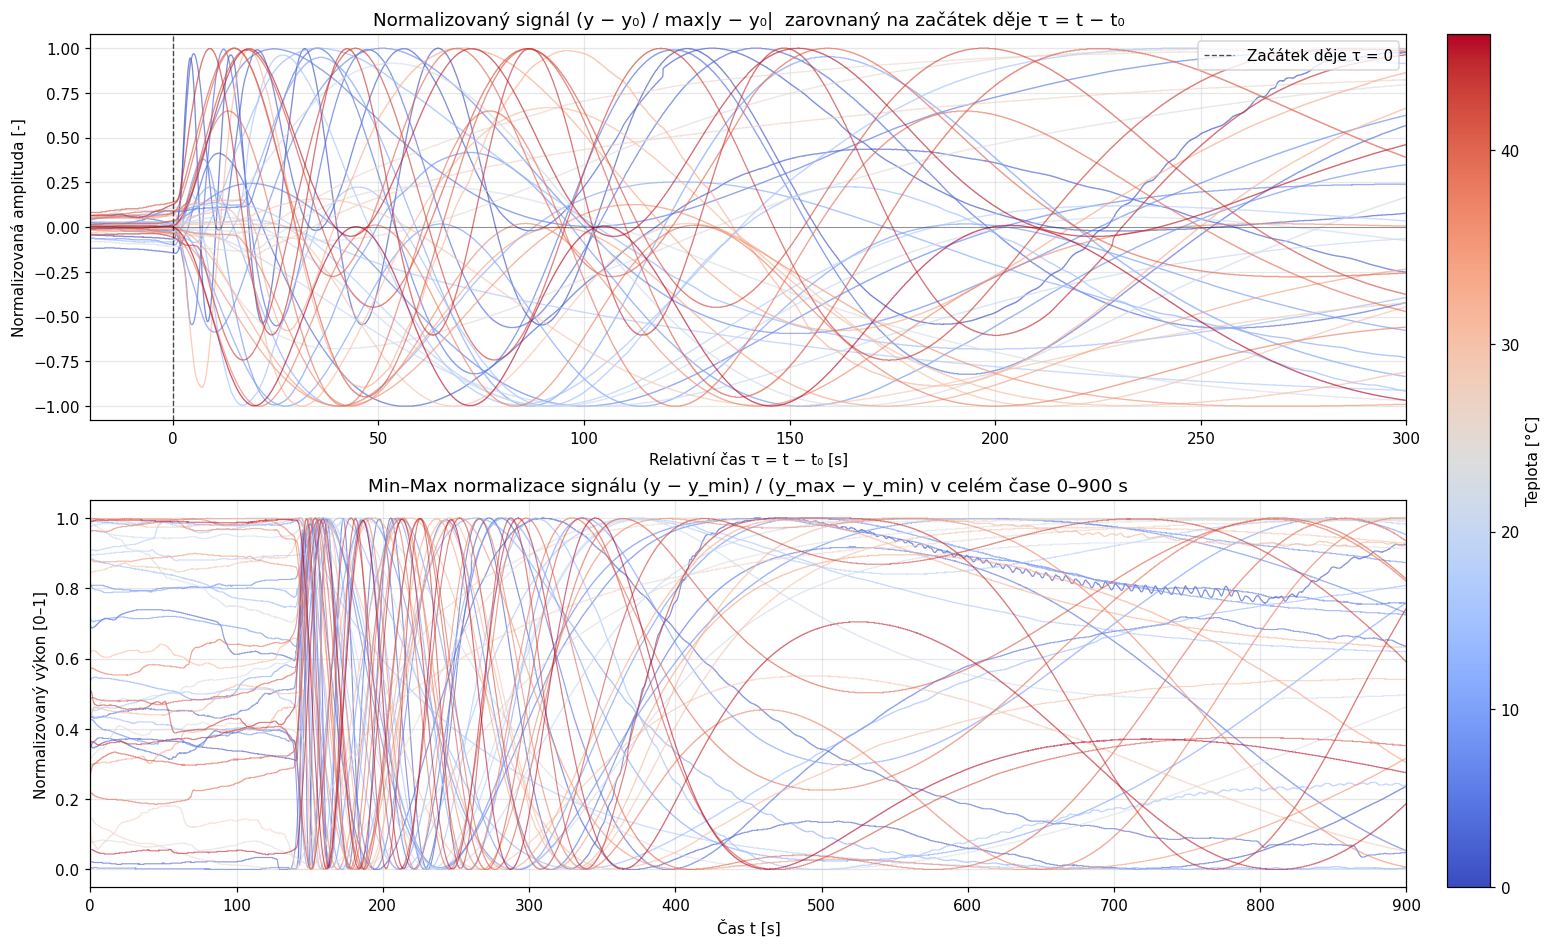

In [2]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8.5), constrained_layout=True)

# Horní graf: (y - y0) / max|y - y0| zarovnáno na t - t0
for temp in temps:
    d = datasets[temp]
    tau = d["t"] - d["t0"]
    mask = (tau >= -20) & (tau <= 300)
    ax1.plot(tau[mask], d["y_norm_centered"][mask], color=cmap(norm_color(temp)), lw=0.85, alpha=0.65)

ax1.axvline(0, color="black", ls="--", lw=0.9, alpha=0.7, label="Začátek děje τ = 0")
ax1.axhline(0, color="black", lw=0.6, alpha=0.4)
ax1.set_title("Normalizovaný signál (y − y₀) / max|y − y₀|  zarovnaný na začátek děje τ = t − t₀")
ax1.set_xlabel("Relativní čas τ = t − t₀ [s]")
ax1.set_ylabel("Normalizovaná amplituda [-]")
ax1.set_xlim(-20, 300)
ax1.set_ylim(-1.08, 1.08)
ax1.legend(loc="upper right")

# Dolní graf: Min–Max normalizace do [0, 1] v celém rozsahu 0–900 s
for temp in temps:
    d = datasets[temp]
    ax2.plot(d["t"], d["y_norm_01"], color=cmap(norm_color(temp)), lw=0.75, alpha=0.6)

ax2.set_title("Min–Max normalizace signálu (y − y_min) / (y_max − y_min) v celém čase 0–900 s")
ax2.set_xlabel("Čas t [s]")
ax2.set_ylabel("Normalizovaný výkon [0–1]")
ax2.set_xlim(0, 900)
ax2.set_ylim(-0.05, 1.05)

cbar = fig.colorbar(sm, ax=[ax1, ax2], pad=0.02)
cbar.set_label("Teplota [°C]")
plt.show()

## 2. Normalizovaný tvar obálky přechodové charakteristiky $v_{\text{norm}}(\tau) \in [0, 1]$

Vyhlazená obálka rychlosti změny $|\Delta y|$ (klouzavý průměr 3 s) vydělená vlastním maximem každého souboru. Zde je porovnán **čistě časový tvar přechodové charakteristiky** (náběh, šířka a doznění) nezávisle na tom, jak velkou amplitudu daná teplota měla.

- Vlevo: teploty **pod 24 °C** (chlazení).
- Vpravo: teploty **nad 24 °C** (ohřev).
- Černá čára = **mediánový tvar** skupiny, šedý pás = **25.–75. percentil**.

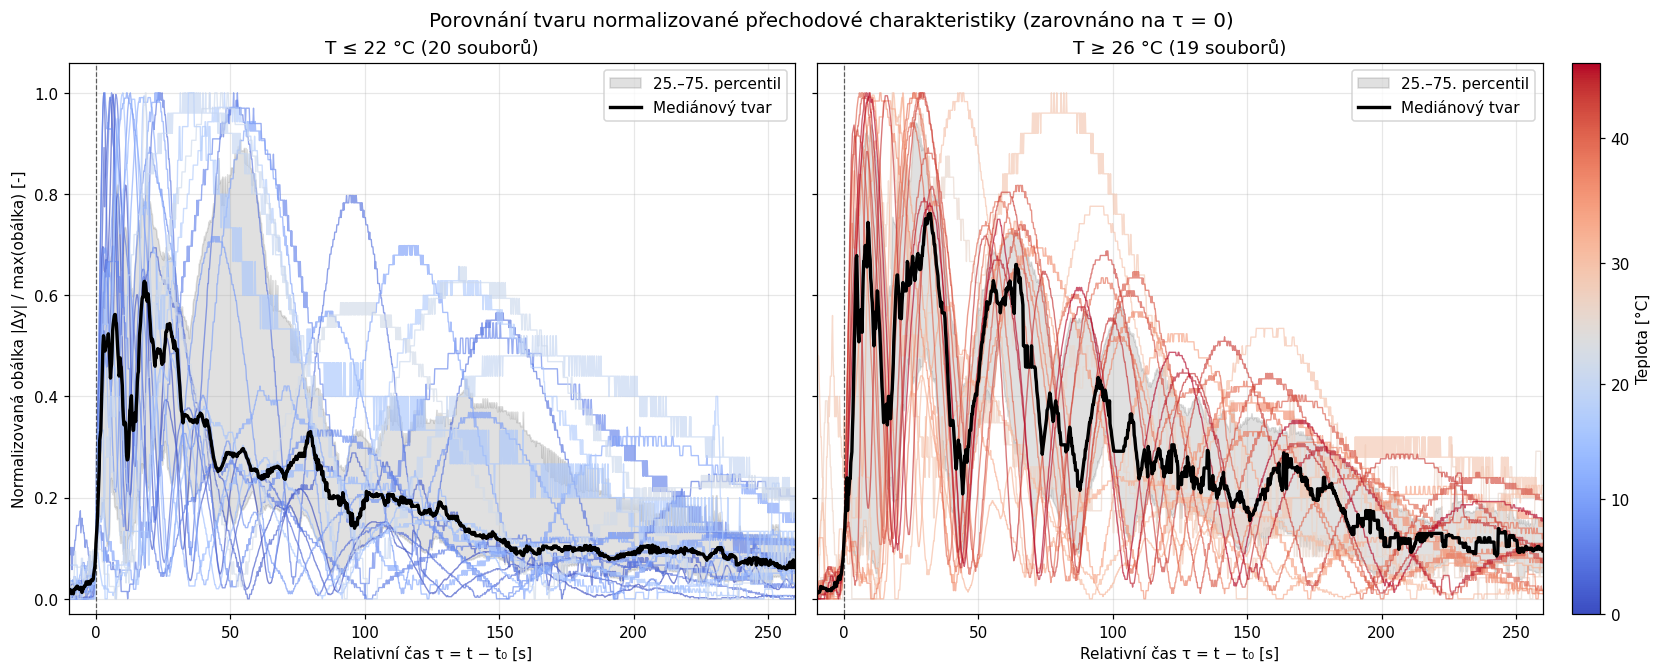

In [3]:
# Společná časová mřížka τ = t - t0 pro výpočet mediánového tvaru a heatmapy
TAU_GRID = np.linspace(-10.0, 260.0, 1351)  # krok 0.2 s

# Volitelně lze vynechat teploty těsně kolem 24 °C (kde je signál téměř nulový / šum)
MIN_DT_FROM_24 = 2  # nastav na 0, pokud chceš zahrnout i 23, 24, 25 °C

cold_temps = [t for t in temps if t <= 24 - MIN_DT_FROM_24]
warm_temps = [t for t in temps if t >= 24 + MIN_DT_FROM_24]

fig, (ax_c, ax_w) = plt.subplots(1, 2, figsize=(15, 6.0), sharey=True, constrained_layout=True)

for ax, group, title in [
    (ax_c, cold_temps, f"T ≤ {24 - MIN_DT_FROM_24} °C ({len(cold_temps)} souborů)"),
    (ax_w, warm_temps, f"T ≥ {24 + MIN_DT_FROM_24} °C ({len(warm_temps)} souborů)"),
]:
    mat = []
    for temp in group:
        d = datasets[temp]
        interp_env = np.interp(TAU_GRID, d["tau_diff"], d["env_norm"], left=np.nan, right=np.nan)
        mat.append(interp_env)
        ax.plot(TAU_GRID, interp_env, color=cmap(norm_color(temp)), lw=0.9, alpha=0.65)

    mat = np.asarray(mat)
    med = np.nanmedian(mat, axis=0)
    q25 = np.nanpercentile(mat, 25, axis=0)
    q75 = np.nanpercentile(mat, 75, axis=0)

    ax.fill_between(TAU_GRID, q25, q75, color="black", alpha=0.12, label="25.–75. percentil")
    ax.plot(TAU_GRID, med, color="black", lw=2.2, label="Mediánový tvar")
    ax.axvline(0, color="black", ls="--", lw=0.8, alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel("Relativní čas τ = t − t₀ [s]")
    ax.set_xlim(-10, 260)
    ax.set_ylim(-0.03, 1.06)
    ax.legend(loc="upper right")

ax_c.set_ylabel("Normalizovaná obálka |Δy| / max(obálka) [-]")
fig.suptitle("Porovnání tvaru normalizované přechodové charakteristiky (zarovnáno na τ = 0)", fontsize=13)

cbar = fig.colorbar(sm, ax=[ax_c, ax_w], pad=0.02)
cbar.set_label("Teplota [°C]")
plt.show()

## 3. Heatmapa normalizovaného tvaru v závislosti na teplotě

Každý řádek představuje jeden soubor (teplotu) normalizovaný na `[0, 1]`. Okamžitě je vidět, jak se mění **délka a profil přechodového děje** se vzdáleností od 24 °C.

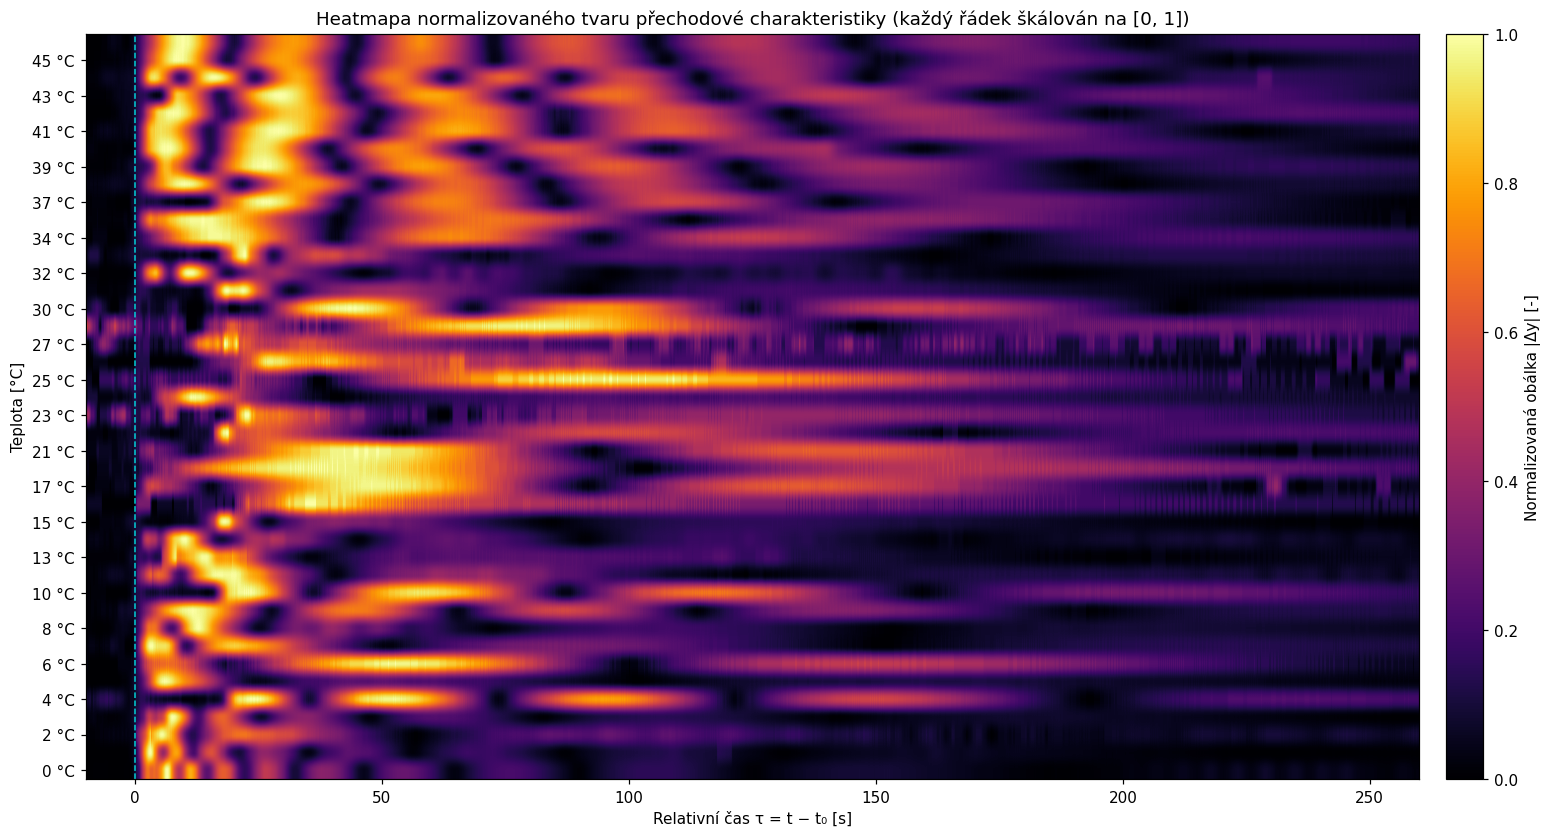

In [4]:
heat_mat = np.vstack([
    np.interp(TAU_GRID, datasets[temp]["tau_diff"], datasets[temp]["env_norm"], left=0.0, right=0.0)
    for temp in temps
])

fig, ax = plt.subplots(figsize=(14, 7.5), constrained_layout=True)
im = ax.imshow(
    heat_mat,
    aspect="auto",
    origin="lower",
    extent=[TAU_GRID[0], TAU_GRID[-1], 0, len(temps)],
    cmap="inferno",
    vmin=0.0,
    vmax=1.0,
)
ax.axvline(0, color="cyan", ls="--", lw=1.0, alpha=0.8)

# Popisky osy Y podle skutečných teplot
tick_idx = np.arange(0, len(temps), 2)
ax.set_yticks(tick_idx + 0.5)
ax.set_yticklabels([f"{temps[i]} °C" for i in tick_idx])

ax.set_title("Heatmapa normalizovaného tvaru přechodové charakteristiky (každý řádek škálován na [0, 1])")
ax.set_xlabel("Relativní čas τ = t − t₀ [s]")
ax.set_ylabel("Teplota [°C]")
ax.grid(False)

cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Normalizovaná obálka |Δy| [-]")
plt.show()

## 4. Kvantitativní porovnání tvaru vs. teplota + detailní překrytí vybraných teplot

- **Doba maxima $\tau_{\text{peak}}$:** jak rychle přechodová charakteristika dosáhne vrcholu.
- **Doba poklesu na 50 % ($\tau_{50}$):** poločas doznění hlavní špičky.
- **Doba 90 % celkové změny ($\tau_{90\%}$):** celková délka přechodového děje.
- Dole: přímé překrytí vybraných teplot (seznam `COMPARE_TEMPS` si můžeš libovolně upravit).

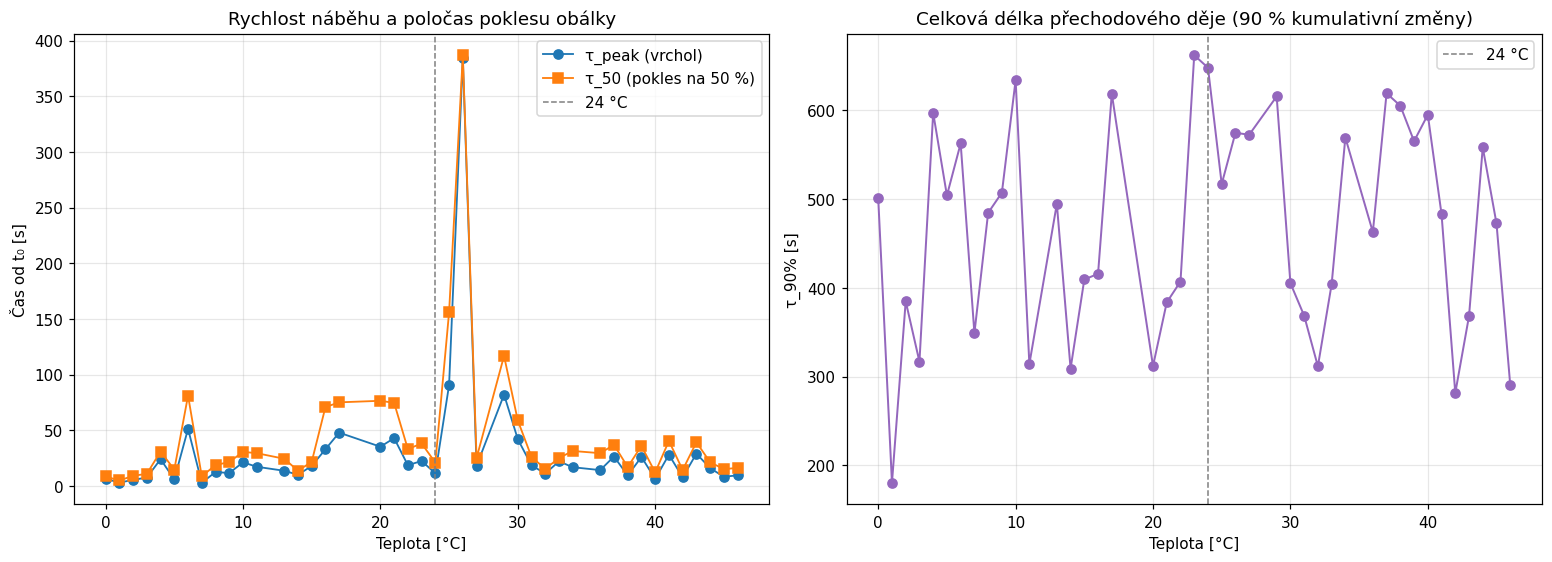

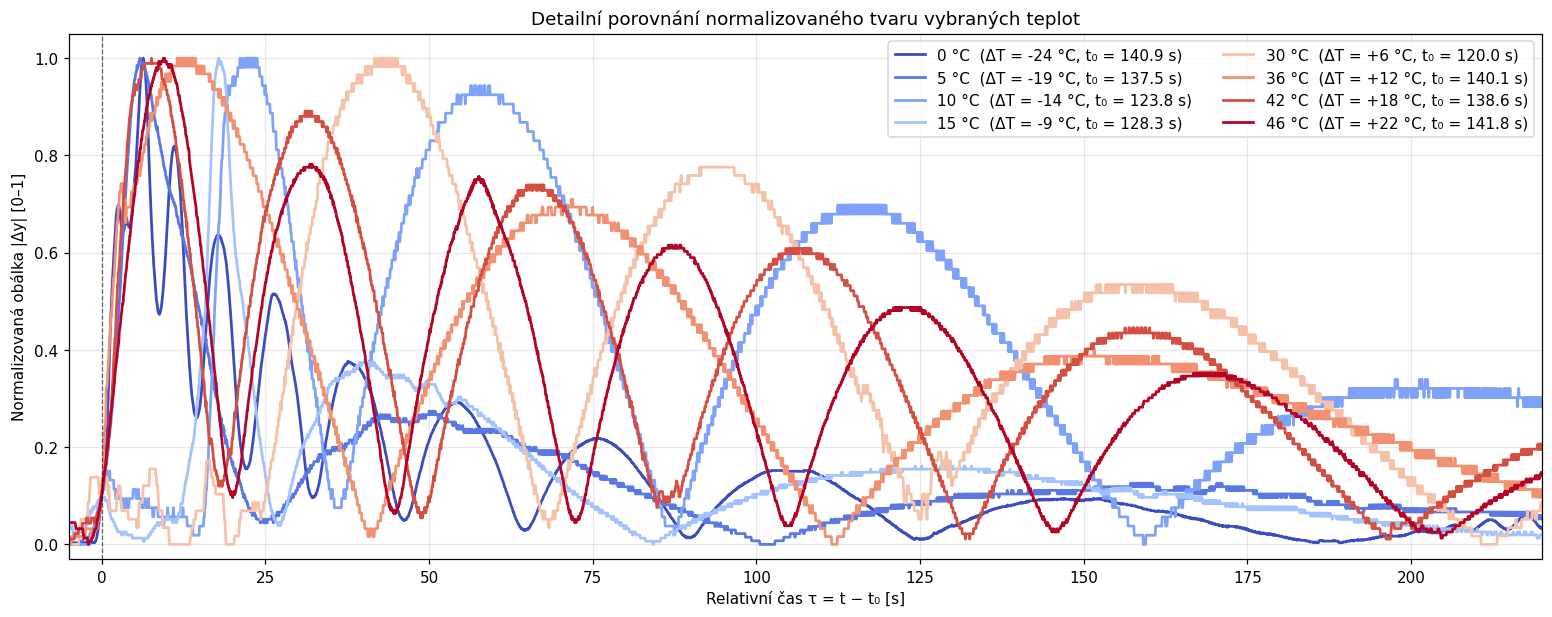

,Teplota [°C],|ΔT| od 24 °C,t0 [s],τ_peak [s],τ_50 [s],τ_10 [s],τ_90%_energie [s],max_obálky [µW]
0,0,24,140.866667,6.333333,8.400000,32.000000,500.600000,1.315556
1,1,23,141.333333,2.933334,4.800000,20.733334,180.466667,1.046667
2,2,22,139.000000,5.333333,9.000000,50.733333,384.800000,0.246667
3,3,21,138.400000,7.466667,10.800000,24.466667,316.800000,0.713333
4,4,20,121.200000,23.933333,30.800000,35.000000,596.866667,0.153333
5,5,19,137.466667,5.800000,14.600000,21.666666,503.933333,0.300000
6,6,18,139.733333,51.200000,81.066667,95.266667,562.533334,0.073333
7,7,17,138.933333,2.733334,8.466667,46.666667,348.866667,0.186667
8,8,16,140.266667,12.466666,18.733333,23.666666,484.333333,0.442222
9,9,15,144.600000,11.466667,21.333333,26.266667,507.066667,0.211111


In [5]:
metrics_df = pd.DataFrame([
    {
        "Teplota [°C]": temp,
        "|ΔT| od 24 °C": abs(temp - 24),
        "t0 [s]": datasets[temp]["t0"],
        "τ_peak [s]": datasets[temp]["tau_peak"],
        "τ_50 [s]": datasets[temp]["tau_50"],
        "τ_10 [s]": datasets[temp]["tau_10"],
        "τ_90%_energie [s]": datasets[temp]["tau_90_energy"],
        "max_obálky [µW]": datasets[temp]["env_max"] * 1e6,
    }
    for temp in temps
])

# --- Graf 4A: Metriky tvaru v závislosti na teplotě ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0), constrained_layout=True)

ax1.plot(metrics_df["Teplota [°C]"], metrics_df["τ_peak [s]"], "o-", label="τ_peak (vrchol)", lw=1.2)
ax1.plot(metrics_df["Teplota [°C]"], metrics_df["τ_50 [s]"], "s-", label="τ_50 (pokles na 50 %)", lw=1.2)
ax1.axvline(24, color="gray", ls="--", lw=1.0, label="24 °C")
ax1.set_title("Rychlost náběhu a poločas poklesu obálky")
ax1.set_xlabel("Teplota [°C]")
ax1.set_ylabel("Čas od t₀ [s]")
ax1.legend()

ax2.plot(metrics_df["Teplota [°C]"], metrics_df["τ_90%_energie [s]"], "o-", color="tab:purple", lw=1.3)
ax2.axvline(24, color="gray", ls="--", lw=1.0, label="24 °C")
ax2.set_title("Celková délka přechodového děje (90 % kumulativní změny)")
ax2.set_xlabel("Teplota [°C]")
ax2.set_ylabel("τ_90% [s]")
ax2.legend()
plt.show()

# --- Graf 4B: Přímé překrytí vybraných teplot (snadná úprava seznamu) ---
COMPARE_TEMPS = [0, 5, 10, 15, 30, 36, 42, 46]
compare_valid = [t for t in COMPARE_TEMPS if t in datasets]

fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)
for temp in compare_valid:
    d = datasets[temp]
    mask = (d["tau_diff"] >= -5) & (d["tau_diff"] <= 220)
    ax.plot(
        d["tau_diff"][mask],
        d["env_norm"][mask],
        color=cmap(norm_color(temp)),
        lw=1.8,
        label=f"{temp} °C  (ΔT = {temp - 24:+d} °C, t₀ = {d['t0']:.1f} s)",
    )

ax.axvline(0, color="black", ls="--", lw=0.8, alpha=0.6)
ax.set_title("Detailní porovnání normalizovaného tvaru vybraných teplot")
ax.set_xlabel("Relativní čas τ = t − t₀ [s]")
ax.set_ylabel("Normalizovaná obálka |Δy| [0–1]")
ax.set_xlim(-5, 220)
ax.set_ylim(-0.03, 1.05)
ax.legend(ncol=2, loc="upper right")
plt.show()

metrics_df.head(15)